# Análise de Cotações PTAX - Banco Central do Brasil
# Usando PySpark com Transformações e Ações
(código utilizado no colab)
============================================
## 1. Instalação e Configuração
============================================

In [11]:
try:
    import google.colab
    IN_COLAB = True
    print(" Ambiente detectado: Google Colab")
    print("Instalando Java e Spark...")
    !apt-get install openjdk-8-jdk-headless -qq > /dev/null
    !wget -q https://archive.apache.org/dist/spark/spark-3.5.0/spark-3.5.0-bin-hadoop3.tgz
    !tar xf spark-3.5.0-bin-hadoop3.tgz
    !pip install -q findspark

    import os
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
    os.environ["SPARK_HOME"] = "/content/spark-3.5.0-bin-hadoop3"

    import findspark
    findspark.init()
    print("✓ Spark configurado com sucesso no Colab!")
except:
    IN_COLAB = False
    print(" Ambiente detectado: Local")
    print("Certifique-se de ter o Java 8 ou 11 instalado")
    print("Verificando Java...")
    import subprocess
    try:
        result = subprocess.run(['java', '-version'], capture_output=True, text=True)
        print("✓ Java encontrado!")
    except:
        print("Java não encontrado. Instale o Java JDK 8 ou 11")
        print("Download: https://www.oracle.com/java/technologies/downloads/")
        raise Exception("Java não instalado")

!pip install pyspark requests -q

import requests
import json
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.window import Window
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

 Ambiente detectado: Google Colab
Instalando Java e Spark...
✓ Spark configurado com sucesso no Colab!


============================================
## 2. Configuração do SPARK
============================================

In [12]:
print("\n Iniciando Spark Session...")

spark = SparkSession.builder \
    .appName("Análise PTAX - Banco Central") \
    .master("local[*]") \
    .config("spark.driver.memory", "2g") \
    .config("spark.executor.memory", "2g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.driver.host", "localhost") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("✓ Spark Session iniciada com sucesso!")
print(f"✓ Versão do Spark: {spark.version}")
print(f"✓ Master: {spark.sparkContext.master}")



 Iniciando Spark Session...
✓ Spark Session iniciada com sucesso!
✓ Versão do Spark: 3.5.0
✓ Master: local[*]


============================================
## 3. Coleta de dados do BC
============================================

In [13]:
url = "https://olinda.bcb.gov.br/olinda/servico/PTAX/versao/v1/odata/CotacaoMoedaPeriodo(moeda=@moeda,dataInicial=@dataInicial,dataFinalCotacao=@dataFinalCotacao)?@moeda='GBP'&@dataInicial='01-01-2023'&@dataFinalCotacao='09-01-2025'&$top=1000&$format=json&$select=paridadeCompra,paridadeVenda,cotacaoCompra,cotacaoVenda,dataHoraCotacao,tipoBoletim"

print("\n Coletando dados da API do Banco Central...")
print(f" Endpoint: PTAX - CotacaoMoedaPeriodo")
print(f" Moeda: GBP (Libra Esterlina)")

response = requests.get(url)

if response.status_code == 200:
    data = response.json()
    records = data['value']
    print(f"✓ Dados coletados com sucesso: {len(records)} registros")
else:
    print(f"✗ Erro ao coletar dados: {response.status_code}")
    raise Exception("Falha na coleta de dados")



 Coletando dados da API do Banco Central...
 Endpoint: PTAX - CotacaoMoedaPeriodo
 Moeda: GBP (Libra Esterlina)
✓ Dados coletados com sucesso: 1000 registros


============================================
## 4. Criação do Dataframe SPARK
============================================

In [14]:
print("\n Criando DataFrame Spark...")

# Converter para DataFrame Pandas primeiro
df_pandas = pd.DataFrame(records)

# Criar DataFrame Spark
df_spark = spark.createDataFrame(df_pandas)

print("\n Schema original do DataFrame:")
df_spark.printSchema()

print("\n Primeiras 5 linhas do DataFrame:")
df_spark.show(5, truncate=False)


 Criando DataFrame Spark...

 Schema original do DataFrame:
root
 |-- paridadeCompra: double (nullable = true)
 |-- paridadeVenda: double (nullable = true)
 |-- cotacaoCompra: double (nullable = true)
 |-- cotacaoVenda: double (nullable = true)
 |-- dataHoraCotacao: string (nullable = true)
 |-- tipoBoletim: string (nullable = true)


 Primeiras 5 linhas do DataFrame:
+--------------+-------------+-------------+------------+-----------------------+-------------+
|paridadeCompra|paridadeVenda|cotacaoCompra|cotacaoVenda|dataHoraCotacao        |tipoBoletim  |
+--------------+-------------+-------------+------------+-----------------------+-------------+
|1.2049        |1.2053       |6.4287       |6.4316      |2023-01-02 10:11:18.511|Abertura     |
|1.2052        |1.2053       |6.4524       |6.4537      |2023-01-02 11:05:17.032|Intermediário|
|1.2047        |1.2052       |6.441        |6.4444      |2023-01-02 12:10:16.594|Intermediário|
|1.2042        |1.2046       |6.4257       |6.4286  

============================================
## 5. Transformações (Lazy Evaluation)
============================================

In [15]:
print("\n" + "="*70)
print(" APLICANDO TRANSFORMAÇÕES NO DATAFRAME (LAZY EVALUATION)")
print("="*70)

# TRANSFORMAÇÃO 1: withColumn - Converter data para timestamp
print("\n1️. TRANSFORMAÇÃO: withColumn() - Convertendo data para timestamp")
df_transformed = df_spark.withColumn(
    "data_cotacao",
    to_timestamp(col("dataHoraCotacao"))
)
print("   ✓ Nova coluna 'data_cotacao' criada")

# TRANSFORMAÇÃO 2: select - Selecionar e renomear colunas relevantes
print("\n2️. TRANSFORMAÇÃO: select() - Selecionando e renomeando colunas")
df_transformed = df_transformed.select(
    col("data_cotacao"),
    col("cotacaoCompra").alias("compra"),
    col("cotacaoVenda").alias("venda"),
    col("paridadeCompra").alias("paridade_compra"),
    col("paridadeVenda").alias("paridade_venda"),
    col("tipoBoletim").alias("tipo_boletim")
)
print("   ✓ Colunas renomeadas e selecionadas")

# TRANSFORMAÇÃO 3: withColumn - Calcular spread (diferença entre venda e compra)
print("\n3️. TRANSFORMAÇÃO: withColumn() - Calculando spread")
df_transformed = df_transformed.withColumn(
    "spread",
    round(col("venda") - col("compra"), 6)
)
print("   ✓ Coluna 'spread' calculada (venda - compra)")

# TRANSFORMAÇÃO 4: withColumn - Extrair informações temporais
print("\n4️. TRANSFORMAÇÃO: withColumn() - Extraindo componentes de data")
df_transformed = df_transformed.withColumn("ano", year(col("data_cotacao"))) \
    .withColumn("mes", month(col("data_cotacao"))) \
    .withColumn("dia", day(col("data_cotacao"))) \
    .withColumn("dia_semana", dayofweek(col("data_cotacao"))) \
    .withColumn("trimestre", quarter(col("data_cotacao")))
print("   ✓ Colunas temporais criadas: ano, mês, dia, dia_semana, trimestre")

# TRANSFORMAÇÃO 5: filter - Filtrar apenas boletim de fechamento
print("\n5️. TRANSFORMAÇÃO: filter() - Filtrando boletim de fechamento")
df_transformed = df_transformed.filter(col("tipo_boletim") == "Fechamento")
print("   ✓ Filtro aplicado: apenas boletins de 'Fechamento'")

# TRANSFORMAÇÃO 6: orderBy - Ordenar por data
print("\n6️. TRANSFORMAÇÃO: orderBy() - Ordenando por data (desc)")
df_transformed = df_transformed.orderBy(col("data_cotacao").desc())
print("   ✓ Dados ordenados por data (mais recente primeiro)")

# TRANSFORMAÇÃO 7: Window Function - Calcular média móvel de 7 dias
print("\n7️. TRANSFORMAÇÃO: Window Function - Média móvel 7 dias")
windowSpec = Window.orderBy("data_cotacao").rowsBetween(-6, 0)
df_transformed = df_transformed.withColumn(
    "media_movel_7d",
    round(avg(col("venda")).over(windowSpec), 4)
)
print("   ✓ Média móvel de 7 dias calculada")

# TRANSFORMAÇÃO 8: Window Function - Calcular variação percentual diária
print("\n8️. TRANSFORMAÇÃO: Window Function - Variação percentual diária")
windowSpec_lag = Window.orderBy("data_cotacao")
df_transformed = df_transformed.withColumn(
    "cotacao_anterior",
    lag(col("venda"), 1).over(windowSpec_lag)
).withColumn(
    "variacao_percentual",
    when(col("cotacao_anterior").isNotNull(),
         round(((col("venda") - col("cotacao_anterior")) / col("cotacao_anterior")) * 100, 4)
    ).otherwise(None)
)
print("   ✓ Variação percentual diária calculada")

# TRANSFORMAÇÃO 9: withColumn - Classificar volatilidade
print("\n9️. TRANSFORMAÇÃO: withColumn() - Classificando volatilidade")
df_transformed = df_transformed.withColumn(
    "volatilidade",
    when(abs(col("variacao_percentual")) >= 2.0, "Alta")
    .when(abs(col("variacao_percentual")) >= 1.0, "Média")
    .when(col("variacao_percentual").isNotNull(), "Baixa")
    .otherwise("N/A")
)
print("   ✓ Coluna 'volatilidade' criada")

# TRANSFORMAÇÃO 10: cache - Persistir DataFrame em memória
print("\n10 TRANSFORMAÇÃO: cache() - Persistindo dados em memória")
df_transformed = df_transformed.cache()
print("   ✓ DataFrame em cache para melhor performance")

print("\n  Todas as transformações foram DEFINIDAS mas ainda NÃO EXECUTADAS!")
print("   (Lazy Evaluation - execução acontece apenas quando uma AÇÃO for chamada)")



 APLICANDO TRANSFORMAÇÕES NO DATAFRAME (LAZY EVALUATION)

1️. TRANSFORMAÇÃO: withColumn() - Convertendo data para timestamp
   ✓ Nova coluna 'data_cotacao' criada

2️. TRANSFORMAÇÃO: select() - Selecionando e renomeando colunas
   ✓ Colunas renomeadas e selecionadas

3️. TRANSFORMAÇÃO: withColumn() - Calculando spread
   ✓ Coluna 'spread' calculada (venda - compra)

4️. TRANSFORMAÇÃO: withColumn() - Extraindo componentes de data
   ✓ Colunas temporais criadas: ano, mês, dia, dia_semana, trimestre

5️. TRANSFORMAÇÃO: filter() - Filtrando boletim de fechamento
   ✓ Filtro aplicado: apenas boletins de 'Fechamento'

6️. TRANSFORMAÇÃO: orderBy() - Ordenando por data (desc)
   ✓ Dados ordenados por data (mais recente primeiro)

7️. TRANSFORMAÇÃO: Window Function - Média móvel 7 dias
   ✓ Média móvel de 7 dias calculada

8️. TRANSFORMAÇÃO: Window Function - Variação percentual diária
   ✓ Variação percentual diária calculada

9️. TRANSFORMAÇÃO: withColumn() - Classificando volatilidade
   ✓ 

============================================
# 6. Ações (Trigger Execution)
============================================


 EXECUTANDO AÇÕES - PROCESSAMENTO REAL DOS DADOS

1️. AÇÃO: count() - Contando total de registros
   Total de registros processados: 200

2️. AÇÃO: show() - Visualizando dados transformados
   Primeiras 10 linhas do DataFrame processado:
+-----------------------+------+------+---------------+--------------+------------+------+----+---+---+----------+---------+--------------+----------------+-------------------+------------+
|data_cotacao           |compra|venda |paridade_compra|paridade_venda|tipo_boletim|spread|ano |mes|dia|dia_semana|trimestre|media_movel_7d|cotacao_anterior|variacao_percentual|volatilidade|
+-----------------------+------+------+---------------+--------------+------------+------+----+---+---+----------+---------+--------------+----------------+-------------------+------------+
|2023-01-02 13:05:57.593|6.434 |6.4369|1.2042         |1.2046        |Fechamento  |0.0029|2023|1  |2  |2         |1        |6.4369        |NULL            |NULL               |N/A         |
|

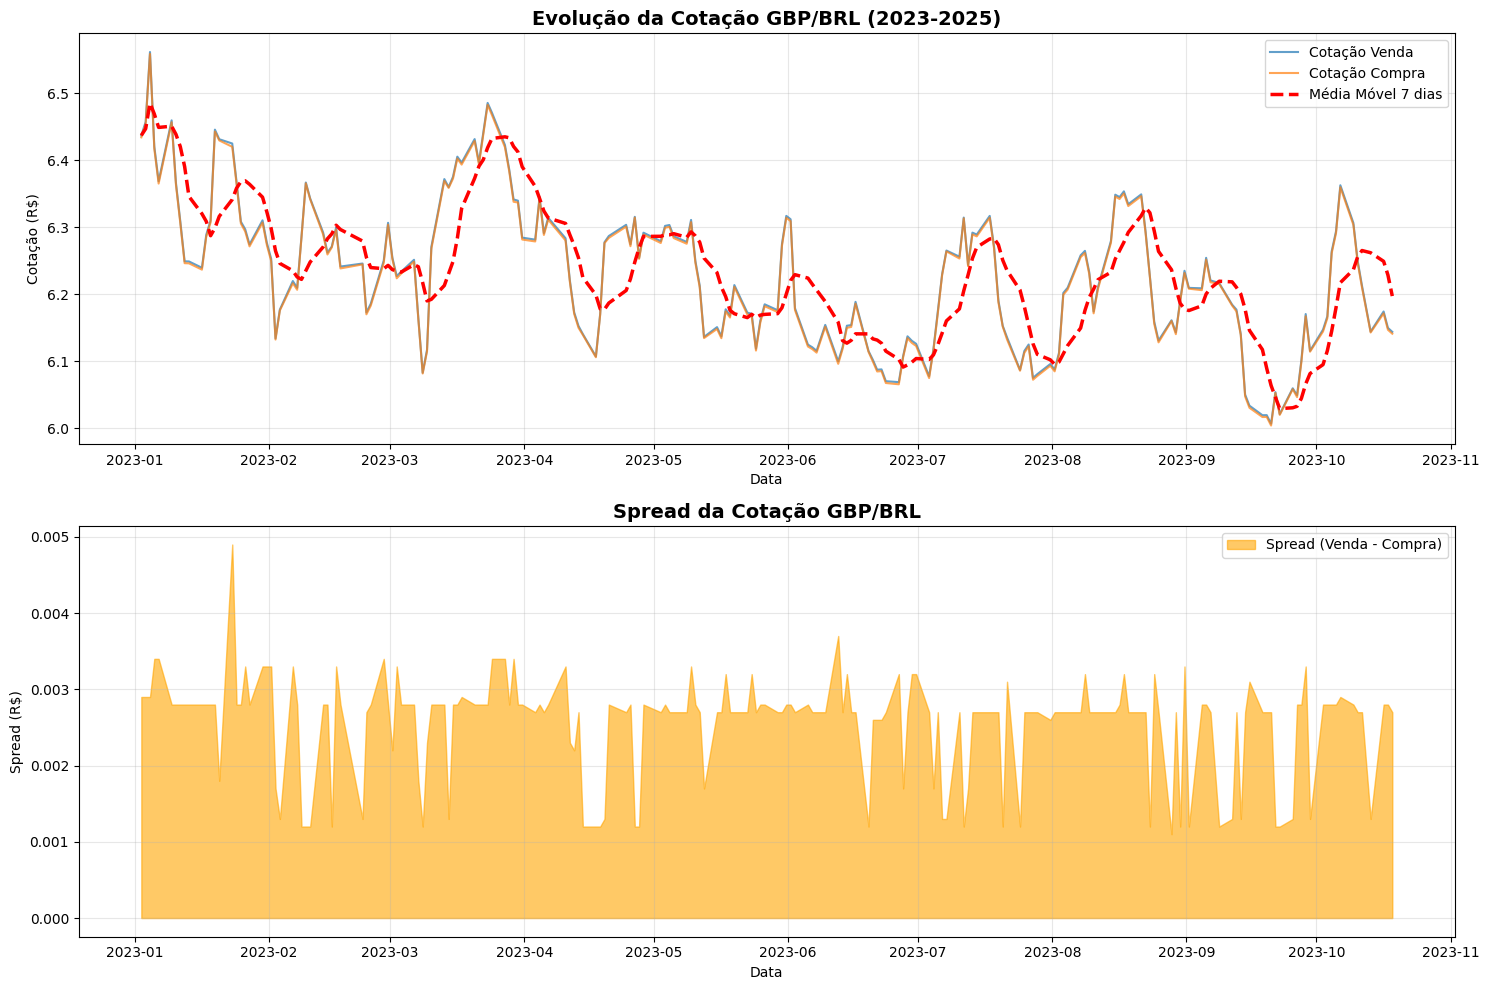

   ✓ Gráficos gerados com sucesso!

8️. AÇÃO: collect() - Análise de volatilidade

   Distribuição de volatilidade:
   • Baixa: 166 dias
   • Média: 29 dias
   • Alta: 4 dias
   • N/A: 1 dias


In [16]:
print("\n" + "="*70)
print(" EXECUTANDO AÇÕES - PROCESSAMENTO REAL DOS DADOS")
print("="*70)

# AÇÃO 1: count() - Contar registros
print("\n1️. AÇÃO: count() - Contando total de registros")
total_registros = df_transformed.count()
print(f"   Total de registros processados: {total_registros}")

# AÇÃO 2: show() - Mostrar dados processados
print("\n2️. AÇÃO: show() - Visualizando dados transformados")
print("   Primeiras 10 linhas do DataFrame processado:")
df_transformed.show(10, truncate=False)

# AÇÃO 3: describe() - Estatísticas descritivas
print("\n3️. AÇÃO: describe() - Estatísticas descritivas")
print("   Análise estatística das cotações:")
df_transformed.select("compra", "venda", "spread", "variacao_percentual").describe().show()

# AÇÃO 4: collect() - Coletar dados agregados por ano
print("\n4️. AÇÃO: collect() - Análise agregada por ano")
analise_anual = df_transformed.groupBy("ano") \
    .agg(
        count("*").alias("qtd_dias"),
        round(avg("venda"), 4).alias("cotacao_media"),
        round(min("venda"), 4).alias("cotacao_min"),
        round(max("venda"), 4).alias("cotacao_max"),
        round(stddev("venda"), 4).alias("desvio_padrao"),
        round(avg("spread"), 6).alias("spread_medio")
    ) \
    .orderBy("ano") \
    .collect()

print("\n    ANÁLISE POR ANO - GBP/BRL (Libra Esterlina):")
print("   " + "-" * 80)
for row in analise_anual:
    print(f"   Ano {row['ano']}:")
    print(f"      • Dias úteis: {row['qtd_dias']}")
    print(f"      • Cotação média: R$ {row['cotacao_media']:.4f}")
    print(f"      • Mínima: R$ {row['cotacao_min']:.4f} | Máxima: R$ {row['cotacao_max']:.4f}")
    print(f"      • Desvio padrão: R$ {row['desvio_padrao']:.4f}")
    print(f"      • Spread médio: R$ {row['spread_medio']:.6f}")
    print()

# AÇÃO 5: first() e take() - Obter registros específicos
print("\n5️. AÇÃO: first() e take() - Cotações mais recentes")
cotacao_mais_recente = df_transformed.first()
print(f"\n  Cotação mais recente (GBP/BRL):")
print(f"   Data: {cotacao_mais_recente['data_cotacao'].strftime('%d/%m/%Y %H:%M:%S')}")
print(f"   Venda: R$ {cotacao_mais_recente['venda']:.4f}")
print(f"   Compra: R$ {cotacao_mais_recente['compra']:.4f}")
print(f"   Spread: R$ {cotacao_mais_recente['spread']:.6f}")
if cotacao_mais_recente['variacao_percentual']:
    print(f"   Variação: {cotacao_mais_recente['variacao_percentual']:.2f}%")

print("\n   Últimas 5 cotações:")
ultimas_5 = df_transformed.take(5)
for i, row in enumerate(ultimas_5, 1):
    var = row['variacao_percentual'] if row['variacao_percentual'] else 0
print(f"   {i}. {row['data_cotacao'].strftime('%d/%m/%Y')}: "
          f"R$ {row['venda']:.4f} {var:+.2f}%")

# AÇÃO 6: Agregação - Análise mensal
print("\n6️. AÇÃO: Agregação - Análise mensal detalhada")
print("   Últimos 12 meses:")
analise_mensal = df_transformed.groupBy("ano", "mes") \
    .agg(
        count("*").alias("dias"),
        round(avg("venda"), 4).alias("media"),
        round(min("venda"), 4).alias("min"),
        round(max("venda"), 4).alias("max"),
        round(stddev("venda"), 4).alias("volatilidade")
    ) \
    .orderBy(col("ano").desc(), col("mes").desc()) \
    .limit(12)

analise_mensal.show(12, truncate=False)

# AÇÃO 7: toPandas() - Converter para visualização
print("\n7️. AÇÃO: toPandas() - Convertendo para visualização gráfica")
df_plot = df_transformed.select("data_cotacao", "venda", "compra", "media_movel_7d") \
    .orderBy("data_cotacao") \
    .toPandas()

print(f"   ✓ {len(df_plot)} registros convertidos para Pandas")

# Criar visualizações
print("\n   Gerando gráficos...")

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Gráfico 1: Evolução da cotação
axes[0].plot(df_plot['data_cotacao'], df_plot['venda'],
             label='Cotação Venda', alpha=0.7, linewidth=1.5)
axes[0].plot(df_plot['data_cotacao'], df_plot['compra'],
             label='Cotação Compra', alpha=0.7, linewidth=1.5)
axes[0].plot(df_plot['data_cotacao'], df_plot['media_movel_7d'],
             label='Média Móvel 7 dias', linewidth=2.5, color='red', linestyle='--')
axes[0].set_title('Evolução da Cotação GBP/BRL (2023-2025)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Data')
axes[0].set_ylabel('Cotação (R$)')
axes[0].legend(loc='best')
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Spread
df_plot['spread'] = df_plot['venda'] - df_plot['compra']
axes[1].fill_between(df_plot['data_cotacao'], df_plot['spread'],
                      alpha=0.6, color='orange', label='Spread (Venda - Compra)')
axes[1].set_title('Spread da Cotação GBP/BRL', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Data')
axes[1].set_ylabel('Spread (R$)')
axes[1].legend(loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("   ✓ Gráficos gerados com sucesso!")

# AÇÃO 8: foreach/foreachPartition simulado com collect
print("\n8️. AÇÃO: collect() - Análise de volatilidade")
analise_volatilidade = df_transformed.groupBy("volatilidade") \
    .agg(count("*").alias("quantidade")) \
    .orderBy(col("quantidade").desc()) \
    .collect()

print("\n   Distribuição de volatilidade:")
for row in analise_volatilidade:
    print(f"   • {row['volatilidade']}: {row['quantidade']} dias")


============================================
## 7. Análises avançadas
============================================

In [17]:
print("\n" + "="*70)
print(" ANÁLISES AVANÇADAS")
print("="*70)

# Top maiores altas
print("\n TOP 10 DIAS COM MAIOR ALTA:")
df_transformed.filter(col("variacao_percentual").isNotNull()) \
    .orderBy(col("variacao_percentual").desc()) \
    .select("data_cotacao", "venda", "variacao_percentual", "volatilidade") \
    .show(10, truncate=False)

# Top maiores quedas
print("\n TOP 10 DIAS COM MAIOR QUEDA:")
df_transformed.filter(col("variacao_percentual").isNotNull()) \
    .orderBy(col("variacao_percentual").asc()) \
    .select("data_cotacao", "venda", "variacao_percentual", "volatilidade") \
    .show(10, truncate=False)

# Análise por dia da semana
print("\n ANÁLISE POR DIA DA SEMANA:")
print("   (1=Domingo, 2=Segunda, ..., 7=Sábado)")
df_transformed.groupBy("dia_semana") \
    .agg(
        count("*").alias("qtd_registros"),
        round(avg("venda"), 4).alias("cotacao_media"),
        round(avg("variacao_percentual"), 4).alias("variacao_media_pct"),
        round(stddev("venda"), 4).alias("volatilidade")
    ) \
    .orderBy("dia_semana") \
    .show()

# Análise por trimestre
print("\n ANÁLISE POR TRIMESTRE:")
df_transformed.groupBy("ano", "trimestre") \
    .agg(
        count("*").alias("dias"),
        round(avg("venda"), 4).alias("media"),
        round(max("venda") - min("venda"), 4).alias("amplitude")
    ) \
    .orderBy("ano", "trimestre") \
    .show()



 ANÁLISES AVANÇADAS

 TOP 10 DIAS COM MAIOR ALTA:
+-----------------------+------+-------------------+------------+
|data_cotacao           |venda |variacao_percentual|volatilidade|
+-----------------------+------+-------------------+------------+
|2023-03-10 13:04:39.316|6.2705|2.506              |Alta        |
|2023-01-19 13:07:18.678|6.4455|2.1441             |Alta        |
|2023-04-19 13:05:45.757|6.2776|1.7357             |Média       |
|2023-03-13 13:07:19.847|6.3718|1.6155             |Média       |
|2023-01-04 13:09:19.572|6.5612|1.6138             |Média       |
|2023-05-30 13:11:51.392|6.275 |1.598              |Média       |
|2023-10-04 13:06:57.406|6.264 |1.5679             |Média       |
|2023-08-03 13:08:03.164|6.2021|1.4609             |Média       |
|2023-01-09 13:07:16.725|6.4593|1.4258             |Média       |
|2023-02-09 13:06:23.349|6.3667|1.2854             |Média       |
+-----------------------+------+-------------------+------------+
only showing top 10 rows


============================================
## 8. Resumo final
============================================

In [18]:
print("\n" + "="*70)
print(" RESUMO DA ANÁLISE - API PTAX BANCO CENTRAL")
print("="*70)

# Estatísticas gerais
stats = df_transformed.agg(
    min("data_cotacao").alias("data_inicio"),
    max("data_cotacao").alias("data_fim"),
    count("*").alias("total_registros"),
    round(avg("venda"), 4).alias("cotacao_media_geral"),
    round(min("venda"), 4).alias("cotacao_minima_historica"),
    round(max("venda"), 4).alias("cotacao_maxima_historica")
).collect()[0]

print(f"\n INFORMAÇÕES GERAIS:")
print(f"   • Período: {stats['data_inicio'].strftime('%d/%m/%Y')} a {stats['data_fim'].strftime('%d/%m/%Y')}")
print(f"   • Total de registros: {stats['total_registros']}")
print(f"   • Cotação média: R$ {stats['cotacao_media_geral']:.4f}")
print(f"   • Mínima histórica: R$ {stats['cotacao_minima_historica']:.4f}")
print(f"   • Máxima histórica: R$ {stats['cotacao_maxima_historica']:.4f}")
print(f"   • Amplitude: R$ {stats['cotacao_maxima_historica'] - stats['cotacao_minima_historica']:.4f}")

print(f"\n TRANSFORMAÇÕES APLICADAS: 10")
print("   1. withColumn() - Conversão de timestamp")
print("   2. select() - Seleção e renomeação")
print("   3. withColumn() - Cálculo de spread")
print("   4. withColumn() - Extração temporal")
print("   5. filter() - Filtro de boletim")
print("   6. orderBy() - Ordenação")
print("   7. Window Function - Média móvel")
print("   8. Window Function - Variação percentual")
print("   9. withColumn() - Classificação de volatilidade")
print("   10. cache() - Persistência em memória")

print(f"\n AÇÕES EXECUTADAS: 8+")
print("   1. count() - Contagem")
print("   2. show() - Visualização")
print("   3. describe() - Estatísticas")
print("   4. collect() - Agregações")
print("   5. first() e take() - Registros específicos")
print("   6. Agregações complexas")
print("   7. toPandas() - Conversão e visualização")
print("   8. Múltiplas análises agregadas")

print(f"\n RECURSOS DA API DO BC UTILIZADOS:")
print("   • Endpoint: PTAX - CotacaoMoedaPeriodo")
print("   • Moeda: GBP (Libra Esterlina)")
print("   • Filtros OData: @moeda, @dataInicial, @dataFinalCotacao")
print("   • Parâmetros: $top=1000, $format=json")
print("   • Select: paridadeCompra, paridadeVenda, cotacaoCompra,")
print("             cotacaoVenda, dataHoraCotacao, tipoBoletim")

print("\n" + "="*70)
print(" ANÁLISE CONCLUÍDA COM SUCESSO!")
print("="*70)


 RESUMO DA ANÁLISE - API PTAX BANCO CENTRAL

 INFORMAÇÕES GERAIS:
   • Período: 02/01/2023 a 18/10/2023
   • Total de registros: 200
   • Cotação média: R$ 6.2303
   • Mínima histórica: R$ 6.0071
   • Máxima histórica: R$ 6.5612
   • Amplitude: R$ 0.5541

 TRANSFORMAÇÕES APLICADAS: 10
   1. withColumn() - Conversão de timestamp
   2. select() - Seleção e renomeação
   3. withColumn() - Cálculo de spread
   4. withColumn() - Extração temporal
   5. filter() - Filtro de boletim
   6. orderBy() - Ordenação
   7. Window Function - Média móvel
   8. Window Function - Variação percentual
   9. withColumn() - Classificação de volatilidade
   10. cache() - Persistência em memória

 AÇÕES EXECUTADAS: 8+
   1. count() - Contagem
   2. show() - Visualização
   3. describe() - Estatísticas
   4. collect() - Agregações
   5. first() e take() - Registros específicos
   6. Agregações complexas
   7. toPandas() - Conversão e visualização
   8. Múltiplas análises agregadas

 RECURSOS DA API DO BC UTIL

In [19]:
# Opcional: Descomentar para finalizar Spark
spark.stop()
print("\n Spark Session encerrada")


 Spark Session encerrada
